<a href="https://colab.research.google.com/github/berevai/METODOS-NUMERICOS/blob/main/M%C3%A9todo%20de%20Neville.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

$\color{red}{\huge \textbf{Interpolación Iterada de Neville}}$

$\color{#0035D9}{\textbf{Algoritmo 3.1 — Burden & Faires, Análisis Numérico, Cap. 3}}$

$\color{#006B35}{\textbf{Mteria:}}$ Métodos Numéricos  
$\color{#006B35}{\textbf{Autor:}}$ *Rubio Ortega Berenice*  
$\color{#006B35}{\textbf{Fecha}}$  19/11/26

$\color{#0035D9}{\textbf{Formulación del problema}}$

Dada una función $f$ de la que solo conocemos sus valores en $n+1$ nodos distintos $x_0, x_1, \dots, x_n$, queremos **evaluar en un punto $x$** el polinomio de interpolación $P$ de grado a lo sumo $n$ que cumple

$$P(x_i) = f(x_i), \qquad i = 0, 1, \dots, n.$$

$\color{#006B35}{\textbf{Idea clave:}}$ no necesitamos construir los coeficientes de $P$; basta con obtener el valor $P(x)$ combinando polinomios de grado menor de forma recursiva.

$\color{#0035D9}{\textbf{El método de Neville}}$

Sea $P_{i-j,\dots,i}$ el polinomio de interpolación que coincide con $f$ en los $j+1$ nodos $x_{i-j},\dots,x_i$. Se cumple la recurrencia

$$P_{i-j,\dots,i}(x)=\frac{(x-x_{i-j})\,P_{i-j+1,\dots,i}(x)-(x-x_i)\,P_{i-j,\dots,i-1}(x)}{x_i-x_{i-j}}.$$

Si denotamos $Q_{i,j}=P_{i-j,\dots,i}(x)$ (polinomio de grado $j$ evaluado en $x$ usando los $j+1$ nodos más recientes hasta $x_i$), entonces:

$$\boxed{Q_{i,0}=f(x_i)}\qquad\qquad \boxed{Q_{i,j}=\frac{(x-x_{i-j})\,Q_{i,j-1}-(x-x_i)\,Q_{i-1,j-1}}{x_i-x_{i-j}}}\quad 1\le j\le i\le n$$

El resultado final es $P(x)=Q_{n,n}$. Los valores se organizan en una tabla triangular inferior:

| $x_i$ | $Q_{i,0}$ | $Q_{i,1}$ | $Q_{i,2}$ | $Q_{i,3}$ | $Q_{i,4}$ |
|:---:|:---:|:---:|:---:|:---:|:---:|
| $x_0$ | $Q_{0,0}$ | | | | |
| $x_1$ | $Q_{1,0}$ | $Q_{1,1}$ | | | |
| $x_2$ | $Q_{2,0}$ | $Q_{2,1}$ | $Q_{2,2}$ | | |
| $x_3$ | $Q_{3,0}$ | $Q_{3,1}$ | $Q_{3,2}$ | $Q_{3,3}$ | |
| $x_4$ | $Q_{4,0}$ | $Q_{4,1}$ | $Q_{4,2}$ | $Q_{4,3}$ | $\color{red}{Q_{4,4}}$ |

$\color{#0035D9}{\textbf{Algorítmo}}$

Importamos librerías:


In [1]:
import numpy as np
import matplotlib.pyplot as plt   # gráficas

# Opcional: pandas slo sirve para mostrar tablas bonitas.
try:
    import pandas as pd
except ImportError:
    pd = None

# Opcional: scipy trae la función de Bessel J0 exacta (para comparar)
try:
    from scipy.special import j0
except ImportError:
    j0 = None

$\color{#0035D9}{\textbf{Función Neville}}$

Notas de sintaxis:
- `def` define una función; los parámetros van entre paréntesis.
- `np.zeros((m, m))` crea una matriz de $m\times m$ llena de ceros.
- Python indexa desde **0**, igual que la notación $x_0,\dots,x_n$ del libro, así que los índices coinciden directamente.
- `range(1, n+1)` genera $1,2,\dots,n$ (el límite superior **no** se incluye).
- `Q[i, j]` accede a la fila `i`, columna `j`.

In [2]:
def neville(x_nodos, f_nodos, x):
    '''
    Interpolación iterada de Neville (Algoritmo 3.1, Burden).

    Parámetros
    ----------
    x_nodos : lista/arreglo con los nodos x_0, ..., x_n
    f_nodos : lista/arreglo con los valores f(x_0), ..., f(x_n)
    x       : punto donde se evalúa el polinomio de interpolación

    Retorna
    -------
    Q : matriz (n+1)x(n+1) triangular inferior; P(x) = Q[n, n]
    '''
    x_nodos = np.asarray(x_nodos, dtype=float)   # convierte a arreglo de reales
    f_nodos = np.asarray(f_nodos, dtype=float)
    n = len(x_nodos) - 1                          # grado máximo del polinomio

    Q = np.zeros((n + 1, n + 1))                  # tabla Q llena de ceros
    Q[:, 0] = f_nodos                             # primera columna: Q_{i,0} = f(x_i)

    # Paso 1 del algoritmo
    for i in range(1, n + 1):                     # i = 1, 2, ..., n
        for j in range(1, i + 1):                 # j = 1, 2, ..., i
            Q[i, j] = ((x - x_nodos[i - j]) * Q[i, j - 1]
                       - (x - x_nodos[i]) * Q[i - 1, j - 1]) / (x_nodos[i] - x_nodos[i - j])

    # Paso 2: salida de la tabla
    return Q

$\color{#0035D9}{\textbf{Prueba: Ejemplo 2 (Burden, p. 89)}}$

Se desea aproximar $f(1.5)$ con los datos de la **Tabla 3.5** (que corresponden a la función de Bessel de primera clase de orden cero, $J_0$):

| $x$ | 1.0 | 1.3 | 1.6 | 1.9 | 2.2 |
|:---:|:---:|:---:|:---:|:---:|:---:|
| $f(x)$ | 0.7651977 | 0.6200860 | 0.4554022 | 0.2818186 | 0.1103623 |

Con $x_0=1.0,\ x_1=1.3,\ x_2=1.6,\ x_3=1.9,\ x_4=2.2$ y $x=1.5$.

In [3]:
# Datos de la Tabla 3.5
x_nodos = [1.0, 1.3, 1.6, 1.9, 2.2]
f_nodos = [0.7651977, 0.6200860, 0.4554022, 0.2818186, 0.1103623]
x = 1.5          # punto de evaluación

Q = neville(x_nodos, f_nodos, x)

Tabla Q completa (compárese con la Tabla 3.6 del libro)

In [4]:
np.set_printoptions(precision=7, suppress=True)

if pd is not None:
    columnas = [f"Q_i,{j}" for j in range(Q.shape[1])]
    tabla = pd.DataFrame(Q, columns=columnas, index=pd.Index(x_nodos, name="x_i"))
    # Los ceros sobre la diagonal (parte no usada) se muestran vacíos
    display(tabla.round(7).replace(0.0, np.nan).fillna("").style.format(precision=7))
else:
    print(Q)

,"Q_i,0","Q_i,1","Q_i,2","Q_i,3","Q_i,4"
x_i,,,,,
1.000000,0.7651977,,,,
1.300000,0.6200860,0.5233449,,,
1.600000,0.4554022,0.5102968,0.5124715,,
1.900000,0.2818186,0.5132634,0.5112857,0.5118127,
2.200000,0.1103623,0.5104270,0.5137361,0.5118302,0.5118200


$\color{#0035D9}{\textbf{Verificación contra los valores del libro}}$

In [5]:
# Valores de la Tabla 3.6 (redondeados a 7 decimales)
Q_libro = np.array([
    [0.7651977, 0,         0,         0,         0        ],
    [0.6200860, 0.5233449, 0,         0,         0        ],
    [0.4554022, 0.5102968, 0.5124715, 0,         0        ],
    [0.2818186, 0.5132634, 0.5112857, 0.5118127, 0        ],
    [0.1103623, 0.5104270, 0.5137361, 0.5118302, 0.5118200],
])

error_max = np.max(np.abs(Q - Q_libro))
print(f"Máxima diferencia con la Tabla 3.6: {error_max:.2e}")
print("¿Coincide con el libro (tolerancia 1e-6)?", error_max < 1e-6)

Máxima diferencia con la Tabla 3.6: 3.33e-08
¿Coincide con el libro (tolerancia 1e-6)? True


$\color{#0035D9}{\textbf{Solución final}}$

El valor del polinomio de interpolación de grado 4 en $x=1.5$ es $P(x)=Q_{4,4}$:

In [6]:
n = len(x_nodos) - 1
P = Q[n, n]

print("=" * 48)
print(f"  P(1.5) = Q[{n},{n}] = {P:.7f}")
print("=" * 48)

if j0 is not None:
    print(f"  Valor exacto f(1.5) = J0(1.5) = {j0(1.5):.7f}")
    print(f"  Error absoluto = {abs(j0(1.5) - P):.2e}")

  P(1.5) = Q[4,4] = 0.5118200
  Valor exacto f(1.5) = J0(1.5) = 0.5118277
  Error absoluto = 7.68e-06


$\color{#006B35}{\textbf{Resultado:}}$
<b></b> &nbsp; $P(1.5)=Q_{4,4}\approx \mathbf{0.5118200}$
<br>El valor real es $J_0(1.5)=0.5118277$, por lo que la aproximación es correcta hasta 5 cifras decimales.
</div>

$\color{#0035D9}{\textbf{Mejorando la aproximación:}}$
añadir un nodo $x_5=2.5$

Si $Q_{4,4}$ no fuese suficientemente precisa, se agrega otro nodo $x_5=2.5$ con $f(2.5)=-0.0483838$ y se calcula una fila más de la tabla (el libro obtiene $Q_{5,5}=0.5118277$).

In [7]:
x_nodos2 = x_nodos + [2.5]
f_nodos2 = f_nodos + [-0.0483838]

Q2 = neville(x_nodos2, f_nodos2, x)

print("Nueva fila (x_5 = 2.5):")
print(Q2[5])
print(f"\nP(1.5) con 6 nodos = Q[5,5] = {Q2[5,5]:.7f}")
print(f"Valor del libro            = 0.5118277")

Nueva fila (x_5 = 2.5):
[-0.0483838  0.4807699  0.5301984  0.511907   0.511843   0.5118277]

P(1.5) con 6 nodos = Q[5,5] = 0.5118277
Valor del libro            = 0.5118277


$\color{#0035D9}{\textbf{Gráfica del polinomio de interpolación}}$

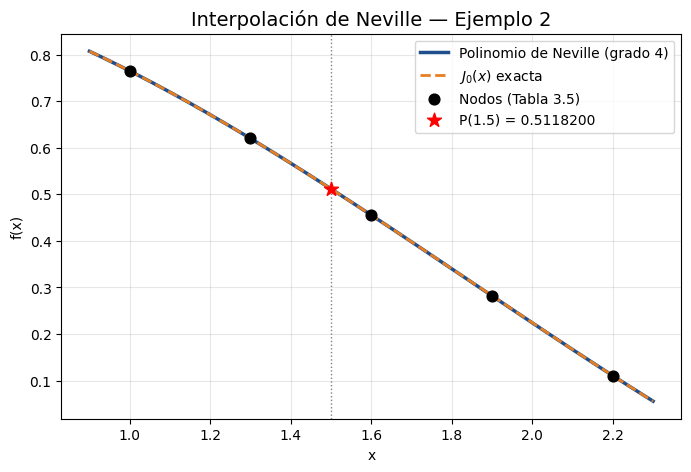

In [8]:
# Evaluamos Neville en muchos puntos para dibujar el polinomio P(t)
t = np.linspace(0.9, 2.3, 300)
P_t = np.array([neville(x_nodos, f_nodos, ti)[-1, -1] for ti in t])

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(t, P_t, color="#1f4e8c", lw=2.5, label="Polinomio de Neville (grado 4)")
if j0 is not None:
    ax.plot(t, j0(t), "--", color="#e67e22", lw=2, label=r"$J_0(x)$ exacta")
ax.scatter(x_nodos, f_nodos, color="black", zorder=5, s=60, label="Nodos (Tabla 3.5)")
ax.scatter([1.5], [P], color="red", zorder=6, s=110, marker="*",
           label=f"P(1.5) = {P:.7f}")
ax.axvline(1.5, color="gray", ls=":", lw=1)

ax.set_title("Interpolación de Neville — Ejemplo 2", fontsize=14)
ax.set_xlabel("x")
ax.set_ylabel("f(x)")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

$\color{#0035D9}{\textbf{En conclusión}}$  

- El método de Neville evalúa $P(x)$ directamente sin calcular los coeficientes del polinomio.
- La implementación reproduce exactamente la **Tabla 3.6** del libro de Burden.
- La mejor aproximación lineal es $Q_{2,1}$ porque $1.5\in[x_1,x_2]=[1.3,1.6]$.
- Añadir nodos solo exige calcular **una fila más** de la tabla, sin repetir el trabajo anterior.
- $\color{#006B35}{\textbf{Solución final:}}$ $P(1.5)=Q_{4,4}\approx 0.5118200$.

**Referencia:** Burden, R. L. & Faires, J. D. *Análisis Numérico*, Cengage Learning, Sección 3.2.